Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.6898 - loss: 0.5648 - val_accuracy: 0.8117 - val_loss: 0.4274
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.8468 - loss: 0.3608 - val_accuracy: 0.8376 - val_loss: 0.3736
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.8855 - loss: 0.2834 - val_accuracy: 0.8242 - val_loss: 0.4043
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.9185 - loss: 0.2154 - val_accuracy: 0.8290 - val_loss: 0.4469
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9482 - loss: 0.1460 - val_accuracy: 0.7970 - val_loss: 0.5468
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.9579 - loss: 0.1160 - val_accuracy: 0.7728 - val_loss: 0.6772
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9731 - loss: 0.0788 - val_accuracy: 0.7943 - val_loss: 0.6957
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9772 -

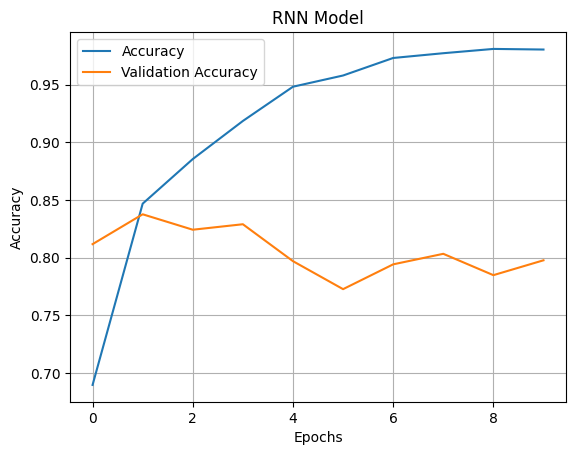

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step

Review: I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ever if the WWF didn't have Lex Luger in the main event against Yokozuna, now for it's time it was ok to have a huge fat man vs a strong man but I'm glad times have changed. It was a terrible main event just like every match Luger is in is terrible. Other matches on the card were Razor Ramon vs Ted Dibiase, Steiner Brothers vs Heavenly Bodies, Shawn Michaels vs Curt Hening, this was the event where Shawn named his big monster of a body guard Diesel, IRS vs 1-2-3 Kid, Bret Hart first takes on Doink then takes on Jerry Lawler and stuff with the Harts and Lawler was always very interesting, then Ludvig Borga destroyed Marty Jannetty, Undertaker took on Giant Gonzalez in another terrible match, The Smoking Gunns and Tatanka took on Bam Bam Bigelow 

In [4]:
import pandas as pd
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense,Embedding


data = pd.read_csv(r"C:\Users\admin\Downloads\Dataset-20261112T113230Z-1-001\Dataset\IMDB\IMDB Dataset.csv")
data.head()
x = data["review"].astype(str)
y = data["sentiment"].map({"positive": 1, "negative": 0})

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 42
)

x_test_original = x_test.copy()
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(x_train)
x_train = pad_sequences(tokenizer.texts_to_sequences(x_train), maxlen=100)
x_test = pad_sequences(tokenizer.texts_to_sequences(x_test), maxlen=100)

model = Sequential([
    Embedding(5000, 32),
    SimpleRNN(32),
    Dense(1, activation = "sigmoid")
])

model.compile(
    optimizer = "Adam",
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs = 10,
    batch_size = 32,
    validation_split = 0.2
)

loss, acc = model.evaluate(x_test, y_test)
print("Accuracy:", acc * 100, "%")

plt.plot(history.history["accuracy"], label = "Accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("RNN Model")
plt.legend()
plt.grid(True)
plt.show()

predictions = model.predict(x_train[:5])
for i in range(5):
    print("\nReview:", x_test_original.iloc[i])
    print("\nPredicated:", "Positive" if predictions[i][0] >= 0.5 else "Negative")
    print("\nActual:", "Positive" if y_test.iloc == 1 else "Negative")